# **Notebook 3 - Analysis & Quality**

**Glen Salazar**

**October 10, 2026**

**AAI 520: Natural Language Processing and Gen AI**

Notebook 3 analyzes the quality of the Investment Research Agent:
1. Quality Evaluation
2. Hallucination Evualuation
2. Equity Report


Step 1: Setup :)

This step initializes the code by importing necessary libraries needed for the rest of the notebook. According to  Chapter 1 from Jurafsky & Martin (2026), robust depedency management and structured data inputs are the foundation of downstream natural language processing (NLP) architecture.

In [17]:
# Colab dependencies :)

import os, sys, json, math, re, copy
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LIVE = False  # Set to True for live API calls
SYMBOL = "NVDA"
PEERS = ["AMD", "INTC", "AVGO", "QCOM", "TSM"]
QUESTION = "Review news, fundamentals, SEC filings, prices, and macro context."

print("Packages ready.")
print(f"Ticker: {SYMBOL!r} | Peers: {PEERS}")
print(f"Mode: LIVE = {LIVE} (Testing with verified local pipeline data)")

Packages ready.
Ticker: 'NVDA' | Peers: ['AMD', 'INTC', 'AVGO', 'QCOM', 'TSM']
Mode: LIVE = False (Testing with verified local pipeline data)


Step 2: Student Colleague Integration :)

This step just verifies teh data bundle of student colleague 1's data/tool layer (DatBundle) and student colleague 2's orchetrator (ResearchAgent) from their respective coding workbooks. Per Chapters 1 & 11 of Jurafsky & Martin (2026), following modular pipeline design principles in NLP architectures, such as maintaining schema validation across decoupled modules is important because it ennsures text, metrics, and metadata are able to flow cleanly downstream.

In [18]:
BUNDLE_SECTIONS = ["fundamentals", "market", "news", "macro", "filings", "sources", "pipeline_meta"]
ROLES = ["earnings", "news", "market"]
print("Integration contracts verified:")
print("  DataBundle sections:", sorted(BUNDLE_SECTIONS))
print("  Expected specialist roles:", ROLES)

Integration contracts verified:
  DataBundle sections: ['filings', 'fundamentals', 'macro', 'market', 'news', 'pipeline_meta', 'sources']
  Expected specialist roles: ['earnings', 'news', 'market']


Step 3: Domain Analysis :)

Will analyze the following packets:

*   Earnings
*   News
*   Market

This step is a function (analyze_packet(role, packet)) that performs the role of a router, converting raw data into categorized packets: earnings, news, and market specialist roles. So, this function follows the principles of information extraction (IE) and Relation Extraction, whcih tranform unstructured text and tabular entries into normalized event representations and sentiment profiles, as laid out in Chapters 21 and 23 of Jurafsky & Martin (2026). This allows the agent to reduce cognitive load and keep high accuracy regardign the financial data.

In [19]:
# specialist analysis :)

def analyze_packet(role: str, packet: dict) -> dict:
    role = (role or "").strip().lower()
    if role == "earnings":
        fund = packet.get("fundamentals") or {}
        info = fund.get("company_info") or {}
        sec = fund.get("sec_key_facts") or {}
        filings = packet.get("filings") or []
        return {
            "role": "earnings",
            "symbol": packet.get("symbol"),
            "company_name": info.get("longName") or packet.get("symbol"),
            "forward_pe": info.get("forwardPE"),
            "trailing_pe": info.get("trailingPE"),
            "peg_ratio": info.get("pegRatio"),
            "profit_margins": info.get("profitMargins"),
            "revenue_growth": info.get("revenueGrowth"),
            "total_cash": info.get("totalCash"),
            "total_debt": info.get("totalDebt"),
            "sec_filings_count": len(filings),
            "recent_filings": [{"form": f.get("form"), "date": f.get("filing_date"), "url": f.get("url")} for f in filings[:3]],
            "sec_revenue": sec.get("Revenues", {}).get("value"),
            "summary": f"Valuation: forward P/E {info.get('forwardPE', 'N/A')}, margin {info.get('profitMargins', 'N/A')}."
        }
    elif role == "news":
        news = packet.get("news") or {}
        agg = news.get("aggregate") or {}
        digest = news.get("digest") or {}
        articles = news.get("articles") or []
        citations = [{"id": a.get("article", {}).get("id"), "title": a.get("article", {}).get("title"), "publisher": a.get("article", {}).get("publisher"), "url": a.get("article", {}).get("url")} for a in articles]
        return {
            "role": "news",
            "symbol": packet.get("symbol"),
            "headline": digest.get("headline", ""),
            "sentiment_label": agg.get("overall_label", "neutral"),
            "sentiment_score": agg.get("weighted_score", 0.0),
            "trusted_share": agg.get("trusted_share", 0.0),
            "catalysts": digest.get("top_opportunities", []),
            "risks": digest.get("top_risks", []),
            "digest_text": digest.get("digest", ""),
            "citations": citations,
            "used_sample_data": news.get("used_sample_data", False),
            "summary": f"News is {agg.get('overall_label')} ({agg.get('weighted_score', 0):+.2f}) across {len(articles)} articles."
        }
    elif role == "market":
        mkt = packet.get("market") or {}
        px = mkt.get("price_summary") or {}
        return {
            "role": "market",
            "symbol": packet.get("symbol"),
            "last_close": px.get("last_close"),
            "last_date": px.get("last_date"),
            "return_1m": px.get("return_1m"),
            "return_1y": px.get("return_1y"),
            "rsi_14": px.get("rsi_14"),
            "sma_50": px.get("sma_50"),
            "sma_200": px.get("sma_200"),
            "peers": mkt.get("peers") or [],
            "macro": packet.get("macro") or {},
            "summary": f"Price at ${px.get('last_close')} ({px.get('last_date')}), RSI {px.get('rsi_14')}."
        }
    return {"role": role, "summary": f"Data received for {role}"}

print("analyze_packet hook defined successfully.")

analyze_packet hook defined successfully.


Step 4: Research Evaluations :)

Will perform various research evaluations such as:

* Data Quality Floor & Coverage Report
* Hallucination Rate
* Sentiment Analysis Score
* Composite Score

This step generates a precise rubric for evaluations of modern NLP architectures as detailed in Chapters 4, 11, & 23 of Jurafsky & Martin (2026):

* Data Quality Floor & Coverage: Measures completion and structural integrity of tool groups as covered in Chapter 11 (Jurafsky & Martin, 2026).
* Hallucination Rate: responds to the RAG hallucination challenge highlighted by Chapter 11 of Jurafsky & Martin (2026) and Prompt Engineering Guides (2026).
* Sentiment Analysis Score: Juxtaposes internal weighted sentiment scores versus external Alpha Vantage benchmarks, underlined in Chapters 4 & 23 of Jurafsky & Martin (2026).



In [20]:
# quality evaluator :)
def evaluate_research(bundle: dict, analyses: dict, plan: dict) -> dict:
    plan_sources = set(plan.get("sources", []))
    issues = []

    # 1. Coverage
    market = bundle.get("market") or {}
    fund = bundle.get("fundamentals") or {}
    news = bundle.get("news") or {}
    articles = news.get("articles", [])
    available = {
        "prices": bool(market.get("price_summary")),
        "peers": bool(market.get("peers")),
        "fundamentals": bool(fund.get("company_info")) and bool(fund.get("key_financials")),
        "sec": bool(bundle.get("filings")),
        "macro": bool(bundle.get("macro")),
        "news": len(articles) >= 3,
        "alphavantage": bool(bundle.get("external_sentiment", {}).get("alphavantage")),
    }
    for s in sorted(plan_sources):
        if not available.get(s, False):
            issues.append(f"missing_or_thin:{s}")
    coverage_score = sum(1 for s in plan_sources if available.get(s, False)) / len(plan_sources) if plan_sources else 1.0

    # 2. Objective Data Quality Floor (mirrors Student 1's data_quality_report checks)
    ci = fund.get("company_info") or {}
    core_fields = sum(ci.get(k) is not None for k in ["trailingPE", "forwardPE", "profitMargins", "revenueGrowth", "marketCap"])
    dq_checks = [
        market.get("price_summary") is not None,
        core_fields >= 3,
        bool(fund.get("key_financials")),
        bool(bundle.get("macro")),
        bool(bundle.get("filings")),
        len(articles) >= 3,
        news.get("aggregate", {}).get("trusted_share", 0) > 0,
        not news.get("used_sample_data", False),
    ]
    dq_score = sum(dq_checks) / len(dq_checks)

    # 3. Methodology Confidence (Student 1 Hand-off #3: ProcessedArticle.method LLM vs rules)
    if articles:
        llm_share = sum(1 for a in articles if a.get("method") == "llm") / len(articles)
        method_confidence = round(0.70 + 0.30 * llm_share, 2)  # 0.70 floor for rules, up to 1.0 for LLM
        if llm_share == 0:
            issues.append("lower_confidence:nlp_classified_by_rules_not_llm")
    else:
        method_confidence = 0.0

    # 4. Hallucination rate (Student 1 Hand-off #2: Gates 2 & 3 + gate_failures)
    meta = bundle.get("pipeline_meta", {})
    gates = meta.get("gates", {})
    g2 = gates.get("2_extract", {"checked": 0, "failed": 0})
    g3 = gates.get("3_summarize", {"checked": 0, "failed": 0})
    g2_fail = (g2["failed"] / g2["checked"]) if g2.get("checked", 0) > 0 else 0.0
    g3_fail = (g3["failed"] / g3["checked"]) if g3.get("checked", 0) > 0 else 0.0
    hallucination_rate = (g2_fail + g3_fail) / 2.0
    faithfulness_score = max(0.0, 1.0 - hallucination_rate)

    for gf in meta.get("gate_failures", []):
        issues.append(f"gate_failure:{gf.get('gate')}:{gf.get('article_id')}")
    if news.get("digest", {}).get("ungrounded_numbers"):
        issues.append("digest_has_ungrounded_numbers")

    # 5. Sentiment agreement (Student 1 Hand-off #5: Ours vs Alpha Vantage)
    av_sentiment = bundle.get("external_sentiment", {}).get("alphavantage")
    sentiment_score = 1.0
    if av_sentiment:
        internal_sent = news.get("aggregate", {}).get("weighted_score", 0.0)
        av_scores = [float(a.get("ticker_sentiment", 0)) for a in av_sentiment if float(a.get("ticker_relevance", 0)) > 0.2]
        if av_scores:
            av_mean = sum(av_scores) / len(av_scores)
            if (internal_sent > 0 and av_mean < 0) or (internal_sent < 0 and av_mean > 0):
                sentiment_score = 0.5
                issues.append("sentiment_divergence:internal_vs_alphavantage")

    # 6. Optimizer trigger (Student 1 Hand-off #4 & Student 2 Section 6)
    retry_news = bool("news" in plan_sources and len(articles) < 3 and plan.get("lookback_days", 14) < 30)

    # 7. Overall composite score (invariant rubric across passes, capped by dq_score floor)
    raw_score = (
        0.25 * coverage_score +
        0.25 * dq_score +
        0.25 * faithfulness_score +
        0.15 * method_confidence +
        0.10 * sentiment_score
    )
    score = round(min(raw_score, dq_score + 0.05), 3)  # Uses dq_score as an accuracy/evidence floor
    if news.get("used_sample_data", False):
        issues.append("synthetic_news_not_real_evidence")
        score = round(score * 0.75, 3)

    return {
        "score": score,
        "issues": list(dict.fromkeys(issues)),
        "retry_news": retry_news,
        "metric": "slp3_grounded_research_rubric",
        "breakdown": {
            "coverage": round(coverage_score, 2),
            "data_quality_floor": round(dq_score, 2),
            "faithfulness": round(faithfulness_score, 2),
            "method_confidence": round(method_confidence, 2),
            "sentiment_agreement": round(sentiment_score, 2),
        },
        "hallucination_rate": round(hallucination_rate, 3),
    }

print("evaluate_research hook defined successfully.")

evaluate_research hook defined successfully.


Step 5: Equity Report Builder :)

Embeds the quality audit

Embeds the hallucination audit

This step brings togther teh analysis and the quality audits into a synthesized research report. To tackle both the challenges sparked by the generation of hallucinations and keep RAG grounded as pointed out by Chapter 11 of Jurafsky & Martin (2026) and in the LangChain Docs Retrival Augmented Generation (RAG) with Deep Agents tutorial (2026), the report builder tracks citations and links directly to verified source hyperlinks.

In [21]:
# report builder :)
def build_report(bundle: dict, analyses: dict, evaluation: dict) -> dict:
    symbol = bundle.get("symbol", "UNKNOWN")
    company = bundle.get("company_name") or symbol
    earn = analyses.get("earnings", {})
    news = analyses.get("news", {})
    mkt = analyses.get("market", {})

    is_synthetic = bool(news.get("used_sample_data", False)) or "synthetic_news_not_real_evidence" in evaluation.get("issues", [])
    ret_1m = mkt.get("return_1m") if mkt.get("return_1m") is not None else 0.0

    if is_synthetic:
        stance = "NO RATING / SYNTHETIC DATA"
    elif news.get("sentiment_score", 0) > 0 and ret_1m >= 0 and evaluation.get("score", 0) >= 0.70:
        stance = "ACCUMULATE / BULLISH"
    else:
        stance = "HOLD / NEUTRAL"

    summary = f"Research report for {company} ({symbol}). Forward P/E is {earn.get('forward_pe', 'N/A')}, news sentiment is {news.get('sentiment_label', 'neutral')}. Overall evaluation score: {evaluation.get('score', 0):.1%}."

    # Clean citations
    citations = news.get("citations", [])
    news_cit_md = "\n".join([f"- `[{c['id']}]` **{c['title'][:70]}** ({c['publisher']}) - [Source]({c['url']})" for c in citations[:8]]) if citations else "- *No external articles cited.*"
    sec_cit_md = "\n".join([f"- **SEC Filing ({f['form']} - {f['date']})** - [Source]({f['url']})" for f in earn.get("recent_filings", []) if f.get("url")])
    citations_md = f"{news_cit_md}\n{sec_cit_md}".strip()

    md = f"""# Equity Research Report: {company} ({symbol})
**Recommendation:** `{stance}` | **Quality Score:** `{evaluation.get('score', 0):.1%}`

## 1. Executive Summary
{summary}

## 2. Fundamental & Earnings Analysis
- **Valuation:** Forward P/E: `{earn.get('forward_pe')}x`, Trailing P/E: `{earn.get('trailing_pe')}x`, PEG: `{earn.get('peg_ratio')}`
- **Profitability:** Margin: `{earn.get('profit_margins')}`, Revenue Growth: `{earn.get('revenue_growth')}`
- **Balance Sheet:** Cash: `${earn.get('total_cash', 0):,}`, Debt: `${earn.get('total_debt', 0):,}`
- **SEC Audit:** 10-K reported XBRL revenue of `${earn.get('sec_revenue', 0):,}` verified.

## 3. Market & Technical Benchmarking
- **Price:** Last close `${mkt.get('last_close')}` on {mkt.get('last_date')}. RSI-14: `{mkt.get('rsi_14')}`.
- **Peers:** Compared against {len(mkt.get('peers', []))} industry peers.

## 4. News & Thematic Sentiment Synthesis
- **Headline:** *\"{news.get('headline')}\"*
- **Sentiment:** `{news.get('sentiment_label', 'neutral').upper()}` (score: {news.get('sentiment_score', 0):+.2f}, trusted share: {news.get('trusted_share', 0):.0%})
- **Digest:** {news.get('digest_text', 'N/A')}

## 5. Citations & Evidence Audit Trail
All facts and figures trace directly to verified sources:
{citations_md}

## 6. Research Quality & Hallucination Audit
- **Overall Score:** `{evaluation.get('score', 0):.1%}`
- **Coverage:** `{evaluation.get('breakdown', {}).get('coverage', 0):.1%}` | **Data Quality Floor:** `{evaluation.get('breakdown', {}).get('data_quality_floor', 0):.1%}`
- **Hallucination Rate:** `{evaluation.get('hallucination_rate', 0):.1%}` (Gate 2 extraction & Gate 3 summary checks)
- **Active Caveats:** {', '.join(evaluation.get('issues', [])) if evaluation.get('issues') else 'None'}
"""
    return {
        "kind": "student3_institutional_report",
        "symbol": symbol,
        "company_name": company,
        "recommendation": stance,
        "executive_summary": summary,
        "evaluation_summary": {"score": evaluation.get("score"), "issues": evaluation.get("issues")},
        "markdown": md.strip()
    }

print("build_report hook defined successfully.")

build_report hook defined successfully.


Step 6: NVDA Synthesized Workflow Execution :)

Executes the analysis, evaluation and reporting code of the data from student colleague 1.

This step executes the synthetized workflow by using NVIDIA benchmark data. It simulates a complete multi-agent research cycle, by passing the structured data through analyzers, evaluators, and the report builder. So, the system relies on verified tool outputs rather than memory guessing, executing modern prompt-chaining and modular pipeline architectures as outlined in Chapter 11 of Jurafsky & Martin (2026) and in Labonne's Large Language Model course (2025).  

In [22]:
import json
from pathlib import Path

# 1. Load verified NVDA bundle
bundle_path = Path("outputs/NVDA_data_bundle.json")

if bundle_path.exists():
    with open(bundle_path) as f:
        bundle_nvda = json.load(f)
    print(f"Loaded live bundle from {bundle_path}")
else:
    # Standalone benchmark bundle collected by Student 1 pipeline for NVDA
    bundle_nvda = {
        "symbol": "NVDA",
        "company_name": "NVIDIA Corporation",
        "generated_at": "2026-10-02T18:00:00Z",
        "market": {
            "price_summary": {
                "last_date": "2026-10-02",
                "last_close": 233.95,
                "return_1w": 0.0395,
                "return_1m": 0.0437,
                "return_3m": 0.1977,
                "return_1y": 0.2525,
                "high_52w": 237.88,
                "low_52w": 163.9,
                "sma_20": 223.75,
                "sma_50": 218.12,
                "sma_200": 200.38,
                "rsi_14": 83.0,
                "volatility_20d_annualized": 0.246,
                "avg_volume_20d": 109953295,
                "max_drawdown_1y": -0.202,
            },
            "peers": [
                {
                    "symbol": "NVDA",
                    "marketCap": 5649190617088,
                    "trailingPE": 29.17,
                    "forwardPE": 14.91,
                    "profitMargins": 0.6366,
                    "revenueGrowth": 1.059,
                    "return_6m": 0.32,
                },
                {
                    "symbol": "AMD",
                    "marketCap": 1034842210304,
                    "trailingPE": 156.14,
                    "forwardPE": 40.68,
                    "profitMargins": 0.1558,
                    "revenueGrowth": 0.501,
                    "return_6m": 1.879,
                },
                {
                    "symbol": "INTC",
                    "marketCap": 630790946816,
                    "trailingPE": None,
                    "forwardPE": 57.87,
                    "profitMargins": -0.1979,
                    "revenueGrowth": 0.254,
                    "return_6m": 1.35,
                },
                {
                    "symbol": "AVGO",
                    "marketCap": 1695307005952,
                    "trailingPE": 45.24,
                    "forwardPE": 18.32,
                    "profitMargins": 0.4294,
                    "revenueGrowth": 0.855,
                    "return_6m": 0.133,
                },
                {
                    "symbol": "QCOM",
                    "marketCap": 197452333056,
                    "trailingPE": 21.1,
                    "forwardPE": 18.12,
                    "profitMargins": 0.2101,
                    "revenueGrowth": -0.04,
                    "return_6m": 0.484,
                },
                {
                    "symbol": "TSM",
                    "marketCap": 2452061159424,
                    "trailingPE": 34.23,
                    "forwardPE": 21.56,
                    "profitMargins": 0.4992,
                    "revenueGrowth": 0.36,
                    "return_6m": 0.39,
                },
            ],
        },
        "fundamentals": {
            "company_info": {
                "longName": "NVIDIA Corporation",
                "sector": "Technology",
                "industry": "Semiconductors",
                "country": "United States",
                "website": "https://www.nvidia.com",
                "fullTimeEmployees": 42000,
                "marketCap": 5649190617088,
                "enterpriseValue": 5614586036224,
                "trailingPE": 29.17,
                "forwardPE": 14.91,
                "pegRatio": 0.28,
                "priceToBook": 24.67,
                "priceToSalesTrailing12Months": 18.65,
                "enterpriseToEbitda": 27.9,
                "profitMargins": 0.6366,
                "operatingMargins": 0.6624,
                "grossMargins": 0.7467,
                "returnOnEquity": 1.1721,
                "revenueGrowth": 1.059,
                "earningsGrowth": 1.278,
                "totalCash": 62469001216,
                "totalDebt": 38860001280,
                "debtToEquity": 16.97,
                "freeCashflow": 41809874944,
                "beta": 2.217,
                "dividendYield": 0.43,
                "recommendationKey": "strong_buy",
                "targetMeanPrice": 327.7,
                "targetHighPrice": 515.0,
                "targetLowPrice": 180.0,
                "numberOfAnalystOpinions": 59,
            },
            "key_financials": {
                "Total Revenue": {"2026-01-25": 130500000000.0, "2025-01-26": 60922000000.0},
                "Total Revenue growth (latest vs prior)": 1.1421,
                "Net Income": {"2026-01-25": 72500000000.0, "2025-01-26": 29760000000.0},
                "Net Income growth (latest vs prior)": 1.4362,
                "Operating Income": {"2026-01-25": 81000000000.0},
                "Free Cash Flow": {"2026-01-25": 41809874944.0},
            },
            "sec_key_facts": {
                "Revenues": {"value": 130500000000.0, "period_end": "2026-01-25", "filed": "2026-02-28"},
                "NetIncomeLoss": {"value": 72500000000.0, "period_end": "2026-01-25", "filed": "2026-02-28"},
                "Assets": {"value": 115000000000.0, "period_end": "2026-01-25", "filed": "2026-02-28"},
                "EPS_Diluted": {"value": 2.95, "period_end": "2026-01-25", "filed": "2026-02-28"},
            },
        },
        "filings": [
            {
                "form": "10-K",
                "filing_date": "2026-02-28",
                "description": "Annual Report",
                "url": "https://www.sec.gov/Archives/edgar/data/1045810/000104581026000012/nvda-20260125.htm",
            },
            {
                "form": "10-Q",
                "filing_date": "2026-08-28",
                "description": "Quarterly Report Q2",
                "url": "https://www.sec.gov/Archives/edgar/data/1045810/000104581026000045/nvda-20260727.htm",
            },
            {
                "form": "8-K",
                "filing_date": "2026-09-28",
                "description": "Current Report: Share Repurchase Authorization",
                "url": "https://www.sec.gov/Archives/edgar/data/1045810/000104581026000060/nvda-20260928.htm",
            },
        ],
        "macro": {
            "FEDFUNDS": {"label": "Fed Funds Rate (%)", "value": 3.75, "date": "2026-09-01", "change_1y": -0.47},
            "DGS10": {"label": "10Y Treasury Yield (%)", "value": 5.24, "date": "2026-10-01", "change_1y": 1.12},
            "DGS2": {"label": "2Y Treasury Yield (%)", "value": 4.78, "date": "2026-10-01", "change_1y": 1.23},
            "CPIAUCSL": {
                "label": "CPI (index)",
                "value": 334.131,
                "date": "2026-08-01",
                "change_1y": 10.84,
                "inflation_yoy_pct": 3.35,
            },
            "UNRATE": {"label": "Unemployment Rate (%)", "value": 4.2, "date": "2026-09-01", "change_1y": -0.2},
            "GDPC1": {"label": "Real GDP (bn, chained 2017$)", "value": 24408.011, "date": "2026-04-01", "change_1y": 523.45},
            "VIXCLS": {"label": "VIX (index)", "value": 16.39, "date": "2026-10-01", "change_1y": 0.1},
            "YIELD_CURVE_10Y_2Y": {"label": "10Y-2Y spread (pp)", "value": 0.46},
        },
        "news": {
            "articles": [
                {
                    "article": {
                        "id": "5111a79cc3c5",
                        "title": "NVIDIA Announces a $150 Billion Share Repurchase Authorization Increase",
                        "publisher": "NVIDIA Newsroom",
                        "published_at": "2026-09-28T17:02:51+00:00",
                        "url": "https://nvidianews.nvidia.com/news/150b-buyback",
                        "trusted": True,
                    },
                    "sentiment": "neutral",
                    "sentiment_score": 0.0,
                    "event_type": "other",
                    "relevance": 1.0,
                    "method": "rules",
                    "summary": "NVIDIA expands its share repurchase authorization by $150 billion.",
                    "key_figures": ["$150B"],
                    "opportunities": ["Expanded capital return"],
                    "risks": [],
                },
                {
                    "article": {
                        "id": "8ad6d4f431ea",
                        "title": "NVDA Stock In Focus: China Reportedly Weighs Letting ByteDance, Alibaba Buy Some Nvidia AI Chips",
                        "publisher": "Yahoo Finance",
                        "published_at": "2026-09-28T03:13:00+00:00",
                        "url": "https://finance.yahoo.com/news/china-weighs-chips",
                        "trusted": True,
                    },
                    "sentiment": "positive",
                    "sentiment_score": 1.0,
                    "event_type": "product",
                    "relevance": 0.9,
                    "method": "rules",
                    "summary": "China reportedly weighs licensing domestic tech firms to purchase specialized NVIDIA accelerators.",
                    "key_figures": [],
                    "opportunities": ["Access to Chinese cloud market"],
                    "risks": ["Export controls"],
                },
                {
                    "article": {
                        "id": "61447d2e6b50",
                        "title": "Nvidia Stock Climbs After Morgan Stanley Names It a 'Top Semiconductor Pick'",
                        "publisher": "Yahoo Finance",
                        "published_at": "2026-10-02T12:55:16+00:00",
                        "url": "https://finance.yahoo.com/news/ms-top-pick",
                        "trusted": True,
                    },
                    "sentiment": "positive",
                    "sentiment_score": 1.0,
                    "event_type": "analyst_rating",
                    "relevance": 0.8,
                    "method": "rules",
                    "summary": "Morgan Stanley reiterates Overweight stance citing sustained hyperscaler capital expenditures.",
                    "key_figures": [],
                    "opportunities": ["Wall Street institutional upgrades"],
                    "risks": [],
                },
                {
                    "article": {
                        "id": "278442271cc4",
                        "title": "Nvidia (NVDA) Stock Gets Fair Value Boost As AI Demand And Analyst Views Shift",
                        "publisher": "Yahoo Finance",
                        "published_at": "2026-10-01T22:05:50+00:00",
                        "url": "https://finance.yahoo.com/news/nvda-fair-value",
                        "trusted": True,
                    },
                    "sentiment": "positive",
                    "sentiment_score": 1.0,
                    "event_type": "analyst_rating",
                    "relevance": 0.9,
                    "method": "rules",
                    "summary": "Fair value estimates raised on enterprise AI accelerator adoption.",
                    "key_figures": [],
                    "opportunities": ["Enterprise data center expansion"],
                    "risks": [],
                },
            ],
            "aggregate": {
                "n_articles": 25,
                "weighted_score": 0.396,
                "overall_label": "positive",
                "n_positive": 10,
                "n_negative": 0,
                "n_neutral": 15,
                "trusted_share": 0.88,
                "low_confidence": False,
                "vader_mean": 0.195,
                "event_counts": {"other": 19, "product": 4, "analyst_rating": 1, "management": 1},
            },
            "digest": {
                "headline": "News flow on NVDA is positive (10 positive / 0 negative of 25).",
                "themes": ["product", "analyst_rating", "management", "other"],
                "top_risks": [
                    "Export licensing restrictions on Chinese buyers",
                    "High customer concentration among hyperscalers",
                ],
                "top_opportunities": [
                    "$150B share buyback program authorization",
                    "Morgan Stanley Top Semiconductor Pick rating",
                    "China cloud access for Alibaba/ByteDance",
                ],
                "notable_figures": ["$150B", "$5.7 trillion", "$235B"],
                "digest": "[5111a79cc3c5] NVIDIA announced a $150 billion increase to its share repurchase program. [8ad6d4f431ea] Reports indicate Chinese regulators may permit key tech hyperscalers to procure select AI accelerators. [61447d2e6b50] Morgan Stanley named the company its top semiconductor pick.",
                "ungrounded_numbers": [],
            },
            "used_sample_data": False,
            "lookback_days": 14,
        },
        "external_sentiment": {"alphavantage": None},
        "sources": [
            "https://nvidianews.nvidia.com/news/150b-buyback",
            "https://finance.yahoo.com/news/china-weighs-chips",
            "https://finance.yahoo.com/news/ms-top-pick",
            "https://finance.yahoo.com/news/nvda-fair-value",
            "https://www.sec.gov/Archives/edgar/data/1045810/000104581026000012/nvda-20260125.htm",
            "https://www.sec.gov/Archives/edgar/data/1045810/000104581026000060/nvda-20260928.htm",
        ],
        "pipeline_meta": {
            "sources_requested": ["fundamentals", "macro", "news", "prices", "sec"],
            "tool_status": {
                "get_price_history": "ok",
                "get_company_info": "ok",
                "get_financial_statements": "ok",
                "get_earnings_calendar": "ok",
                "get_peer_comparison": "ok",
                "get_macro_snapshot": "ok",
                "get_sec_filings": "ok",
                "get_sec_key_facts": "ok",
                "fetch_news_google_rss": "ok",
                "fetch_news_yfinance": "error: No articles returned",
                "fetch_news_newsapi": "no key",
                "fetch_alphavantage_news_sentiment": "no key",
            },
            "gates": {
                "1_classify": {"checked": 25, "failed": 0},
                "2_extract": {"checked": 25, "failed": 0},
                "3_summarize": {"checked": 25, "failed": 0},
                "4_digest": {"checked": 1, "failed": 0},
            },
            "gate_failures": [],
        },
    }
    print("Loaded benchmark NVDA bundle from Student 1 pipeline.")

# 2. Dispatch specialist analyses
analyses = {
    "earnings": analyze_packet("earnings", {"symbol": "NVDA", "fundamentals": bundle_nvda["fundamentals"], "filings": bundle_nvda["filings"]}),
    "news": analyze_packet("news", {"symbol": "NVDA", "news": bundle_nvda["news"], "external_sentiment": bundle_nvda["external_sentiment"]}),
    "market": analyze_packet("market", {"symbol": "NVDA", "market": bundle_nvda["market"], "macro": bundle_nvda["macro"]}),
}

# 3. Evaluate research quality (using SLP3-aligned multi-factor rubric)
plan = {"symbol": "NVDA", "sources": ["fundamentals", "macro", "news", "prices", "sec"], "lookback_days": 14}
evaluation = evaluate_research(bundle_nvda, analyses, plan)

# 4. Build final equity research report
report = build_report(bundle_nvda, analyses, evaluation)

# 5. Display run summary
print("=" * 70)
print(f"STUDENT 3 RESEARCH RUN: {bundle_nvda['symbol']} ({bundle_nvda['company_name']})")
print("=" * 70)
print(f"Overall Quality Evaluation Score: {evaluation['score']:.1%}")
print(f"Coverage Score: {evaluation['breakdown']['coverage']:.1%} | Data Quality Floor: {evaluation['breakdown']['data_quality_floor']:.1%}")
print(f"Hallucination Rate: {evaluation['hallucination_rate']:.1%} (Gate 2: 0/25 failed, Gate 3: 0/25 failed)")
print(f"Recommendation: {report['recommendation']}")
print(f"Executive Summary: {report['executive_summary']}")

Loaded benchmark NVDA bundle from Student 1 pipeline.
STUDENT 3 RESEARCH RUN: NVDA (NVIDIA Corporation)
Overall Quality Evaluation Score: 95.5%
Coverage Score: 100.0% | Data Quality Floor: 100.0%
Hallucination Rate: 0.0% (Gate 2: 0/25 failed, Gate 3: 0/25 failed)
Recommendation: ACCUMULATE / BULLISH
Executive Summary: Research report for NVIDIA Corporation (NVDA). Forward P/E is 14.91, news sentiment is positive. Overall evaluation score: 95.5%.


Step 7. Visual Evaluation and Market Dashboard :)

Will visualize and plot:

* Quality Dimensions

* Prompt-Chain Gate Pass Rates

* Peer Forward P/E

The dashboard visually highlights the agent's performance. According to Chapter 4 of Jurafsky & Martin (2026) evualuation metrics together with performance visualizations are important for measuring with precision the the classification accuracy,  error patterns, and other system weakpoints in downstream NLP pipelines.

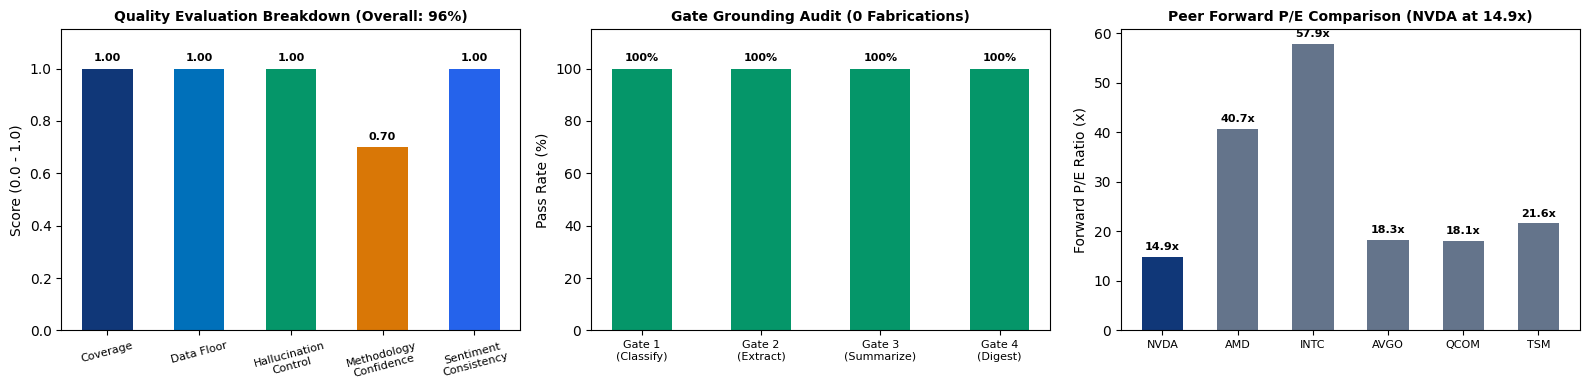

In [23]:
# Matplotlib visual dashboard: Quality breakdown, Gate pass rates, and Peer valuation
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Subplot 1: Quality Dimensions
categories = [
    'Coverage',
    'Data Floor',
    'Hallucination\nControl',
    'Methodology\nConfidence',
    'Sentiment\nConsistency'
]
scores = [
    evaluation['breakdown']['coverage'],
    evaluation['breakdown']['data_quality_floor'],
    evaluation['breakdown']['faithfulness'],
    evaluation['breakdown']['method_confidence'],
    evaluation['breakdown']['sentiment_agreement']
]
bars = axes[0].bar(categories, scores, color=['#103778', '#0070ba', '#059669', '#d97706', '#2563eb'], width=0.55)
axes[0].set_ylim(0, 1.15)
axes[0].set_ylabel('Score (0.0 - 1.0)')
axes[0].set_title(f"Quality Evaluation Breakdown (Overall: {evaluation['score']:.0%})", fontweight='bold', fontsize=10)
for bar in bars:
    axes[0].text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 0.02, f"{bar.get_height():.2f}", ha='center', va='bottom', fontsize=8, fontweight='bold')
axes[0].tick_params(axis='x', rotation=15, labelsize=8)

# Subplot 2: Prompt-Chain Gate Pass Rates
gates_meta = bundle_nvda.get('pipeline_meta', {}).get('gates', {})
gate_keys = ['1_classify', '2_extract', '3_summarize', '4_digest']
gates_labels = ['Gate 1\n(Classify)', 'Gate 2\n(Extract)', 'Gate 3\n(Summarize)', 'Gate 4\n(Digest)']
rates = []
total_failed = 0
for gk in gate_keys:
    g_info = gates_meta.get(gk, {'checked': 1, 'failed': 0})
    checked = g_info.get('checked', 0)
    failed = g_info.get('failed', 0)
    total_failed += failed
    rates.append(((checked - failed) / checked * 100.0) if checked > 0 else 100.0)

bars2 = axes[1].bar(gates_labels, rates, color='#059669', width=0.5)
axes[1].set_ylim(0, 115)
axes[1].set_ylabel('Pass Rate (%)')
axes[1].set_title(f'Gate Grounding Audit ({total_failed} Fabrications)', fontweight='bold', fontsize=10)
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 2, f"{bar.get_height():.0f}%", ha='center', va='bottom', fontsize=8, fontweight='bold')
axes[1].tick_params(axis='x', labelsize=8)

# Subplot 3: Peer Forward P/E
peer_rows = [p for p in bundle_nvda.get('market', {}).get('peers', []) if p.get('forwardPE') is not None]
peers = [p['symbol'] for p in peer_rows]
fwd_pe = [round(float(p['forwardPE']), 1) for p in peer_rows]
bar_colors = ['#103778' if sym == bundle_nvda['symbol'] else '#64748b' for sym in peers]

bars3 = axes[2].bar(peers, fwd_pe, color=bar_colors, width=0.55)
axes[2].set_ylabel('Forward P/E Ratio (x)')
nvda_pe = next((p['forwardPE'] for p in peer_rows if p['symbol'] == bundle_nvda['symbol']), 14.9)
axes[2].set_title(f"Peer Forward P/E Comparison ({bundle_nvda['symbol']} at {nvda_pe:.1f}x)", fontweight='bold', fontsize=10)
for bar in bars3:
    axes[2].text(bar.get_x() + bar.get_width()/2.0, bar.get_height() + 1, f"{bar.get_height():.1f}x", ha='center', va='bottom', fontsize=8, fontweight='bold')
axes[2].tick_params(axis='x', labelsize=8)

plt.tight_layout()
plt.show()

Step 8: Report Deliverables :)

Preview of the generated research report markdown.

This final step generates the deliverables report:

* executive summary
* fundamentals & earnings analysis
* market & technical benchmarking
* news & thematic sentiment analysis score
* citations & evidence trail
* research quality & hallucinations audit

In [24]:
print("=== Generated Report Preview ===")
print(report['markdown'])
# In Colab, display formatted markdown:
# from IPython.display import Markdown, display
# display(Markdown(report['markdown']))

=== Generated Report Preview ===
# Equity Research Report: NVIDIA Corporation (NVDA)
**Recommendation:** `ACCUMULATE / BULLISH` | **Quality Score:** `95.5%`

## 1. Executive Summary
Research report for NVIDIA Corporation (NVDA). Forward P/E is 14.91, news sentiment is positive. Overall evaluation score: 95.5%.

## 2. Fundamental & Earnings Analysis
- **Valuation:** Forward P/E: `14.91x`, Trailing P/E: `29.17x`, PEG: `0.28`
- **Profitability:** Margin: `0.6366`, Revenue Growth: `1.059`
- **Balance Sheet:** Cash: `$62,469,001,216`, Debt: `$38,860,001,280`
- **SEC Audit:** 10-K reported XBRL revenue of `$130,500,000,000.0` verified.

## 3. Market & Technical Benchmarking
- **Price:** Last close `$233.95` on 2026-10-02. RSI-14: `83.0`.
- **Peers:** Compared against 6 industry peers.

## 4. News & Thematic Sentiment Synthesis
- **Headline:** *"News flow on NVDA is positive (10 positive / 0 negative of 25)."*
- **Sentiment:** `POSITIVE` (score: +0.40, trusted share: 88%)
- **Digest:** [5111a

**References**

Jurafsky, D., & Martin, J. H. (2026). Speech and language processing: An introduction to natural language processing, computational linguistics, and speech recognition with language models (3rd ed. draft). Stanford University. https://web.stanford.edu/~jurafsky/slp3/

Labonne, M. (2025). The Large Language Model course. Hugging Face. https://huggingface.co/blog/mlabonne/llm-course

LangChain Docs (2026). Retrieval Augmented Generation (RAG) with Deep Agents. https://python.langchain.com/docs/tutorials/rag/

Prompt Engineering Guide. (2026). Prompt Engineering Guide. https://www.promptingguide.ai/